# Análise exploratória: Breast Cancer Wisconsin
## 1. Conhecendo os dados

In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/data.csv")
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


### 1.1 Quantas linhas e colunas? Os tipos estão corretos?

In [5]:
print(df.shape)   # formato (linhas, colunas)
df.info()       # tipos e contagem de não nulos

(569, 33)
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             56

### 1.2 Há valores nulos?

In [6]:
df.isnull().sum()   # nulos por coluna

id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst      0
Unnamed:

### 1.3 Há duplicatas?

In [7]:
print(df.duplicated().sum())           # linhas inteiras repetidas
print(df["id"].duplicated().sum())     # ids repetidos

0
0


### 1.4 Conclusões

1. São 569 linhas de pacientes e 33 colunas. Os valores da coluna "diagnosis" possuem valores "M" e "B", que precisam ser convertidos para que o modelo consiga entender (0 para B e 1 para M). São 10 medidas x 3 versões (média, erro padrão e pior valor) = 30 colunas.
2. A Unnamed: 32 possui as 569 linhas nulas que foi gerada pela formatação do arquivo.
3. Não há linhas repetidas e não há ids repetidos.
4. Há 2 colunas que não são features: id e a Unnamed: 32. A coluna id representa o identificador do paciente e a Unnamed: 32 foi gerada pela formatação do arquivo. Elas saem do modelo pois o id tem valores, mas são arbitrários e não tem relação com o tumor, podendo resultar em um aprendizado de um padrão falso do modelo que não generaliza para pacientes novos. E a coluna Unnamed: 32 deve ser removida pois não tem informação nenhuma (100% nula).
5. Para o próximo passo, será necessário remover a coluna de id, para não haver a possibilidade do modelo "decorar" os números de identificação que não tem nada a ver com os diagnósticos; remover a coluna Unnamed: 32 que está vazia; converter com uma tabela de conversão a coluna de diagnosis, que atualmente está com os valores "M" e "B", para os valores numéricos "0" e "1" (sendo M=1 e B=0).


## 2. Contagem e proporção
### 2.1 As classes estão balanceadas?

In [8]:
print(df["diagnosis"].value_counts())
print((df["diagnosis"].value_counts(normalize=True) * 100).round(1))




diagnosis
B    357
M    212
Name: count, dtype: int64
diagnosis
B    62.7
M    37.3
Name: proportion, dtype: float64


### 2.2 Gráficos

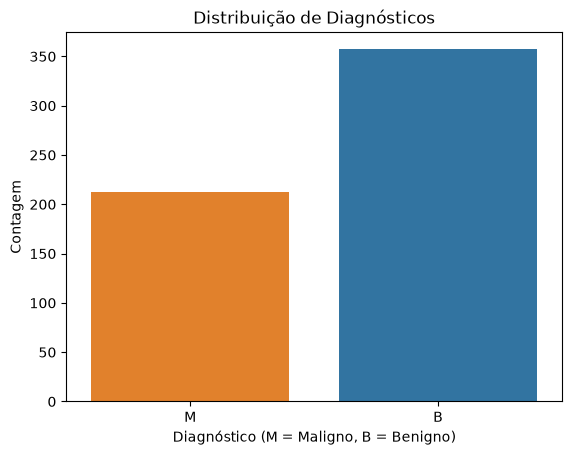

In [30]:
sns.countplot(x="diagnosis", data=df, hue="diagnosis", legend=False, palette={"M": "tab:orange", "B": "tab:blue"})
plt.title("Distribuição de Diagnósticos")
plt.xlabel("Diagnóstico (M = Maligno, B = Benigno)")
plt.ylabel("Contagem")
plt.savefig("../reports/figures/diagnosis_countplot.png", dpi=150, bbox_inches='tight')
plt.show()

### 2.3 Conclusão

1. A contagem de acordo com a base é de 37,3% de casos malignos e 62,7% de casos benignos.
2. Está levemente desbalanceado considerando que 37/63 estão mais próximos do 50/50, do que um caso forte como 95/5.
3. Se houver um sorteio de teste sem cuidado, a proporção de malignos pode ser menor do que o calculado, distorcendo a avaliação. Para evitar isso, utilizaremos o stratify para manter o percentual de 37,3% de casos malignos e 62,7% de casos benignos. Só o cuidado no split vai bastar, pois após o stratify, as proporções dos benignos e malignos estarão mantidas conforme proporção inicial. Considerando esta proporção, o aprendizado para reconhecer o padrão da classe menor será o bastante, sendo cerca de 170 malignos no treino, o suficiente para aprender o padrão. Num 95/5 seriam só uns 28.
4. Observando a acurácia, apenas chutando a classe maior, ele alcançaria 62,7% sem aprender nada, sendo necessário conferir o recall dos malignos, pois pode esconder cânceres não detectados. E neste caso, é mais grave dizer "benigno" para um maligno, sendo necessário acompanhar a métrica de falsos negativos.

## 3. Distribuições e escala
### 3.1 As features estão na mesma escala?

In [29]:
df.drop(columns=['id','Unnamed: 32']).describe().T 

,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture_mean,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter_mean,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area_mean,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness_mean,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness_mean,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity_mean,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave points_mean,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry_mean,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
fractal_dimension_mean,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


### 3.2 O que o describe mostra

Comparando as features: area_mean x concavity_mean x smoothness_mean

area_mean -> min = 143.5 ; max = 2501
concavity_mean -> min = 0.00 ; max = 0.42
smoothness_mean -> min = 0.05 ; max = 0.16

Nestas comparações, conseguimos observar que as features possuem escalas discrepantes. Como por exemplo, o valor max da area_mean (2501) é aproximadamente 6000 vezes maior do que o max do concavity_mean (0.42), assim como o min de smoothness_mean (0.05) é aproximadamente 2900 vezes menor do que o min de area_mean.

### 3.3 Histogramas

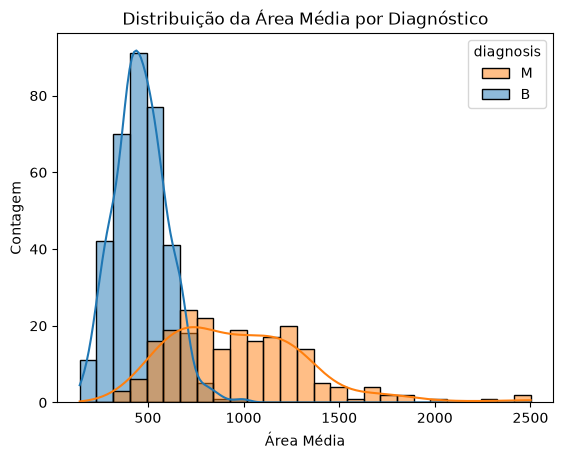

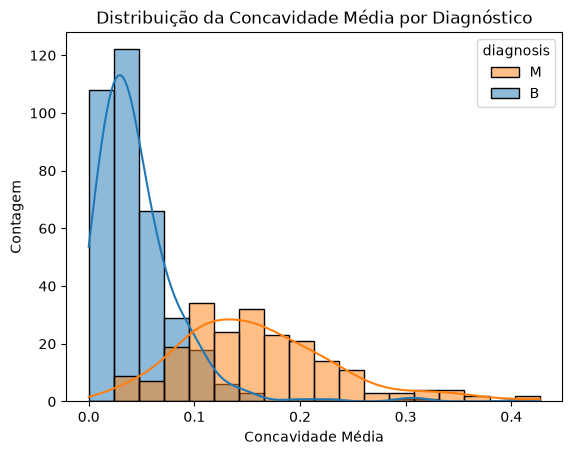

In [36]:
sns.histplot(data=df, x="area_mean", hue="diagnosis", palette={"M": "tab:orange", "B": "tab:blue"}, kde=True)
plt.title("Distribuição da Área Média por Diagnóstico")
plt.xlabel("Área Média")
plt.ylabel("Contagem")
plt.savefig("../reports/figures/distribuicao_area_media.png", dpi=150, bbox_inches='tight')
plt.show()

sns.histplot(data=df, x="concavity_mean", hue="diagnosis", palette={"M": "tab:orange", "B": "tab:blue"}, kde=True)
plt.title("Distribuição da Concavidade Média por Diagnóstico")
plt.xlabel("Concavidade Média")
plt.ylabel("Contagem")
plt.savefig("../reports/figures/distribuicao_concavidade_media.png", dpi=150, bbox_inches='tight')
plt.show()

### Conclusão

1. As features escolhidas para a verificação da distribuição e escala são min e max:


Valores de:

| feature | mean | std | min | 50% | max |
|area_mean|654.889104|351.914129|143.500000|551.100000|2501.00000|
|concavity_mean|0.088799|0.079720|0.000000|0.061540|0.42680|


2. Caso estes valores não forem padronizados, conforme explicado no tópico 3.2, com as grandes diferenças nos valores das features selecionadas, o area_mean dominaria o modelo, e essa feature sozinha não é o suficiente para identificar se um tumor é benigno ou maligno.

3. Observando as distribuições acima, é possível identificar que a média de area_mean (654.88) está acima da mediana (551.10), indicando que a cauda está para a direita, ou seja, há poucos valores muito altos, assim como a média de concavity_mean (0.089) está acima da mediana (0.062), possuindo poucos valores muito altos.

4. De acordo com o hue, as cores da feature area_mean ficam separadas (benigno entre 250 e 1000; maligno entre 300 e 2500; misturado entre 300 a 1000), indicando que uma feature forte mas que possui uma área de mistura, assim como na feature de concavidade (benigno entre 0.0 e 0.13; maligno entre 0.03 e 0.4; misturado entre 0.03 e 0.13).

5. Com isso, a decisão de pré-processamento seria utilizar um StandardScaler, na qual ele padroniza os valores para deixar as variáveis numéricas com a média igual a 0 e desvio padrão igual a 1, evitando que as features com escalas maiores dominem as features que possuem valores mais baixos. O fit deve acontecer apenas em X_train para não ocorrer de vazar a média e o desvio para os testes.